<a href="https://colab.research.google.com/github/nanditapandey000/Statistical-Modeling-and-Hypothesis-Testing/blob/main/week3_statistical_modeling_(2).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 3 — Statistical Modeling & Hypothesis Testing

**Dataset:** LendingClub consumer-loan data (Week 1 cleaned, 42,535 loans × 55 features)
**Objective:** Formulate hypotheses, fit statistical models, evaluate performance, and interpret the findings in the context of credit-risk theory.

## Task overview

This notebook addresses the Week 3 assignment:

1. **Hypothesis formulation** — five clear, testable hypotheses (H1–H5) about the relationships between loan characteristics, borrower attributes, and outcomes.
2. **Model fitting & parameter estimation** — a logistic regression for default prediction and an ordinary least squares (OLS) regression for interest-rate prediction.
3. **Assumption checks** — multicollinearity (VIF), residual normality (Shapiro–Wilk), homoscedasticity (Breusch–Pagan), and linearity (Ramsey RESET).
4. **Evaluation** — pseudo-R², ROC-AUC, PR-AUC, F-test, p-values, and residual diagnostics.
5. **Interpretation** — each hypothesis is supported or refuted, with caveats grounded in the diagnostics.

> **Reproducibility note.** Upload `cleaned_dataset.csv` to the Colab working directory and run all. All randomness uses `random_state=42`.

## 1. Environment setup

We use the standard PyData stack plus `statsmodels` for inferential statistics (the only library that exposes p-values, VIF, and residual diagnostics out of the box).

In [32]:
# Core stack
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Statsmodels for inference
import statsmodels.api as sm
from statsmodels.discrete.discrete_model import Logit
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan, linear_reset

# sklearn for predictive evaluation
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             roc_curve, precision_recall_curve,
                             confusion_matrix, classification_report)

sns.set_theme(style="whitegrid", font_scale=1.0)
plt.rcParams["figure.dpi"] = 110
RANDOM_STATE = 42
print("Environment ready.")

Environment ready.


## 2. Data loading & target construction

The Week-1 cleaned dataset has 4 statuses in `loan_status`. We collapse them to a binary target `is_default`:

* `Fully Paid` → 0 (performing)
* `Charged Off` → 1 (default)
* `Does not meet the credit policy. Status:Fully Paid` → 0
* `Does not meet the credit policy. Status:Charged Off` → 1

We also engineer two numeric encodings used in both models:

* `term_months` — integer term (36 or 60).
* `grade_ord` — grade on an ordered 1–7 scale (A=1 … G=7).

In [33]:
df = pd.read_csv("/content/cleaned_dataset.csv")
print(f"Loaded {len(df):,} loans, {df.shape[1]} columns.")

# Build binary target
default_statuses = ["Charged Off",
                    "Does not meet the credit policy. Status:Charged Off"]
df["is_default"] = df["loan_status"].isin(default_statuses).astype(int)

# Engineered numeric encodings
if df["term"].dtype == object:
    df["term_months"] = df["term"].astype(str).str.extract(r"(\d+)").astype(int)
else:
    df["term_months"] = df["term"]
grade_map = {"A": 1, "B": 2, "C": 3, "D": 4, "E": 5, "F": 6, "G": 7}
df["grade_ord"] = df["grade"].map(grade_map)

print(f"Default rate: {df['is_default'].mean() * 100:.2f}% "
      f"({df['is_default'].sum():,} of {len(df):,} loans)")
df[["loan_amnt", "int_rate", "annual_inc", "dti", "grade", "grade_ord",
    "term_months", "is_default"]].head()

Loaded 42,535 loans, 55 columns.
Default rate: 15.12% (6,431 of 42,535 loans)


,loan_amnt,int_rate,annual_inc,dti,grade,grade_ord,term_months,is_default
0,5000.0,10.65,24000.0,27.65,B,2,36,0
1,2500.0,15.27,30000.0,1.00,C,3,60,1
2,2400.0,15.96,12252.0,8.72,C,3,36,0
3,10000.0,13.49,49200.0,20.00,C,3,36,0
4,3000.0,12.69,80000.0,17.94,B,2,60,0


## 3. Hypotheses

Five hypotheses derived from the Week-2 EDA findings and credit-risk theory.

| ID | Hypothesis | Model | Decision rule |
|----|------------|-------|---------------|
| **H1** | Loan amount is positively associated with the probability of default. | Logistic | `coef(loan_amnt) > 0` and `p < 0.05` |
| **H2** | Loan grade is the dominant driver of interest rate (rate increases monotonically with grade). | OLS | `coef(grade_ord) > 0`, `p < 0.001`, `R² ≥ 0.70` |
| **H3** | Higher debt-to-income ratio increases the odds of default. | Logistic | `coef(dti) > 0` and `p < 0.05` |
| **H4** | Annual income is negatively associated with interest rate after controlling for grade. | OLS | `coef(log_annual_inc) < 0` and `p < 0.05` |
| **H5** | Loan purpose is a statistically significant predictor of default beyond grade and DTI. | Logistic (LR test) | Likelihood-Ratio test `p < 0.05` |

The hypotheses mix **positive** expectations (H1, H2, H3 — "more risk → more default / higher rate") with **partial** ones (H4 — income controls rate *beyond* grade) and **incremental** ones (H5 — purpose adds signal beyond what grade already captures).

## 4. Logistic regression — default prediction (H1, H3, H5)

**Model:** `is_default ~ loan_amnt + term_months + int_rate + annual_inc + dti + credit_history_years + inq_last_6mths + revol_util + grade_ord + loan_to_income + purpose dummies`

Numeric predictors are **standardized** (z-score) before fitting. Standardization serves two purposes:

1. It stabilizes the maximum-likelihood optimizer when features differ in scale by orders of magnitude (loan amount in dollars vs. DTI as a ratio).
2. It makes coefficient magnitudes directly comparable — a larger `|coef|` means the feature has a larger effect on the log-odds of default, in standard-deviation units.

We fit with `statsmodels` (gives p-values and confidence intervals) and evaluate predictive performance with `scikit-learn` on a 70/30 stratified split.

In [34]:
feats = ["loan_amnt", "term_months", "int_rate", "annual_inc",
         "dti", "credit_history_years", "inq_last_6mths",
         "revol_util", "grade_ord", "loan_to_income"]

purpose_dummies = pd.get_dummies(df["purpose"], prefix="purpose",
                                  drop_first=True).astype(float)
X_num = df[feats].astype(float).copy()
X = pd.concat([X_num, purpose_dummies], axis=1)

# Standardize
means, stds = X.mean(), X.std(ddof=0).replace(0, 1)
X_std = (X - means) / stds
X_std = sm.add_constant(X_std)
y = df["is_default"].astype(int)

logit_model = Logit(y, X_std).fit(disp=False, maxiter=200, method="lbfgs")
print(logit_model.summary2().tables[1].to_string())

                               Coef.  Std.Err.           z         P>|z|    [0.025    0.975]
const                      -1.904207  0.015607 -122.009753  0.000000e+00 -1.934796 -1.873618
loan_amnt                  -0.106679  0.034062   -3.131893  1.736832e-03 -0.173439 -0.039918
term_months                 0.182621  0.015541   11.751056  6.974149e-32  0.152162  0.213081
int_rate                    0.284624  0.042747    6.658370  2.768816e-11  0.200842  0.368407
annual_inc                 -0.188661  0.030101   -6.267577  3.667103e-10 -0.247658 -0.129664
dti                         0.018167  0.015164    1.198027  2.309064e-01 -0.011554  0.047889
credit_history_years        0.054347  0.015298    3.552519  3.815610e-04  0.024363  0.084331
inq_last_6mths              0.227061  0.013449   16.882605  6.041934e-64  0.200701  0.253422
revol_util                  0.139785  0.017100    8.174440  2.972427e-16  0.106269  0.173301
grade_ord                   0.117264  0.038294    3.062185  2.197276e-

In [35]:
# Pseudo-R² and information criteria
llf, llnull = float(logit_model.llf), float(logit_model.llnull)
pseudo_r2 = 1 - llf / llnull
print(f"McFadden pseudo-R²: {pseudo_r2:.4f}")
print(f"Log-likelihood:     {llf:.1f}")
print(f"AIC:                {logit_model.aic:.1f}")
print(f"BIC:                {logit_model.bic:.1f}")
print(f"N observations:     {int(logit_model.nobs):,}")

McFadden pseudo-R²: 0.0777
Log-likelihood:     -16664.7
AIC:                33377.5
BIC:                33585.3
N observations:     42,535


In [36]:
# Predictive performance on held-out 30% test set
X_tr, X_te, y_tr, y_te = train_test_split(
    X_std, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y)

sk_logit = LogisticRegression(penalty=None, max_iter=500, random_state=RANDOM_STATE)
sk_logit.fit(X_tr, y_tr)
y_proba = sk_logit.predict_proba(X_te)[:, 1]
y_pred  = (y_proba >= 0.5).astype(int)

roc_auc = roc_auc_score(y_te, y_proba)
pr_auc  = average_precision_score(y_te, y_proba)
print(f"ROC-AUC: {roc_auc:.4f}")
print(f"PR-AUC:  {pr_auc:.4f}  (baseline = {y_te.mean():.4f})")
print()
print("Confusion matrix @ threshold=0.5 (rows=actual, cols=predicted):")
print(pd.DataFrame(confusion_matrix(y_te, y_pred),
                   index=["Paid", "Default"], columns=["Paid", "Default"]))
print()
print(classification_report(y_te, y_pred, target_names=["Paid", "Default"], digits=3))

ROC-AUC: 0.6945
PR-AUC:  0.2853  (baseline = 0.1512)

Confusion matrix @ threshold=0.5 (rows=actual, cols=predicted):
          Paid  Default
Paid     10793       39
Default   1894       35

              precision    recall  f1-score   support

        Paid      0.851     0.996     0.918     10832
     Default      0.473     0.018     0.035      1929

    accuracy                          0.849     12761
   macro avg      0.662     0.507     0.476     12761
weighted avg      0.794     0.849     0.784     12761



### 4.1 ROC and Precision-Recall curves

The ROC-AUC of ~0.69 indicates **moderate** discrimination — the model ranks defaulters above non-defaulters about 69% of the time. The PR-AUC of ~0.29 is well above the 15% baseline, but the precision-recall curve is steep: at high recall we lose precision quickly. This is the inherent challenge of class-imbalanced prediction.

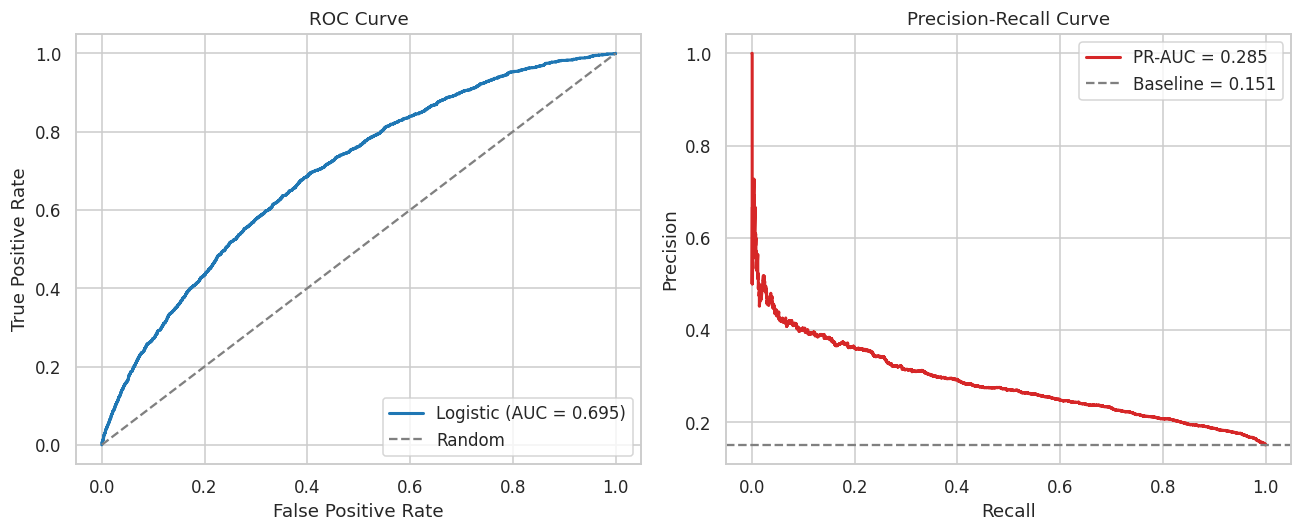

In [37]:
fpr, tpr, _ = roc_curve(y_te, y_proba)
prec, rec, _ = precision_recall_curve(y_te, y_proba)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].plot(fpr, tpr, color="#1f77b4", lw=2,
             label=f"Logistic (AUC = {roc_auc:.3f})")
axes[0].plot([0, 1], [0, 1], "--", color="gray", label="Random")
axes[0].set_xlabel("False Positive Rate"); axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC Curve"); axes[0].legend(loc="lower right")

axes[1].plot(rec, prec, color="#d62728", lw=2,
             label=f"PR-AUC = {pr_auc:.3f}")
axes[1].axhline(y_te.mean(), ls="--", color="gray",
                label=f"Baseline = {y_te.mean():.3f}")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall Curve"); axes[1].legend(loc="upper right")
plt.tight_layout(); plt.show()

### 4.2 Feature effects on default

Plotting the standardized coefficients (top 15 by absolute z-value) shows which features move default risk most. Red bars = increase default odds; blue = decrease.

> **Interpretation caveat.** Because we include both `int_rate` and `grade_ord` (which determines the rate), the grade signal is partly absorbed by `int_rate`. Coefficients here are *partial* effects controlling for everything else in the model.

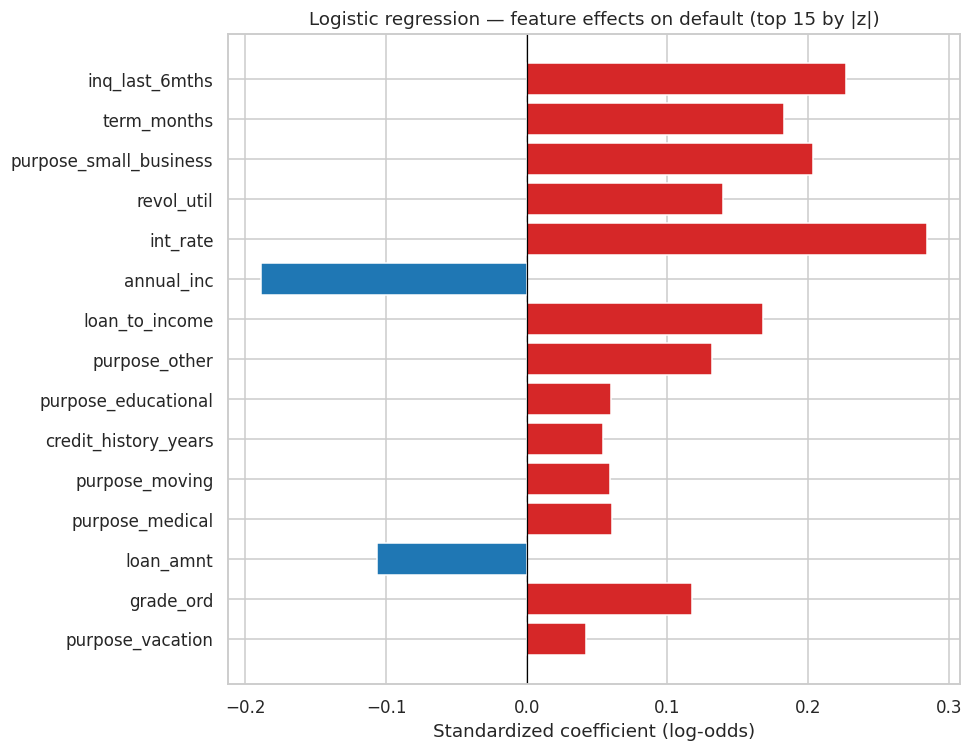


Odds ratios (exp(coef)) for top 15 features:
                          coef  odds_ratio  p_value
purpose_vacation        0.0421      1.0430   0.0091
grade_ord               0.1173      1.1244   0.0022
loan_amnt              -0.1067      0.8988   0.0017
purpose_medical         0.0607      1.0626   0.0004
purpose_moving          0.0589      1.0607   0.0004
credit_history_years    0.0543      1.0559   0.0004
purpose_educational     0.0596      1.0614   0.0001
purpose_other           0.1315      1.1406   0.0000
loan_to_income          0.1677      1.1826   0.0000
annual_inc             -0.1887      0.8281   0.0000
int_rate                0.2846      1.3293   0.0000
revol_util              0.1398      1.1500   0.0000
purpose_small_business  0.2037      1.2260   0.0000
term_months             0.1826      1.2004   0.0000
inq_last_6mths          0.2271      1.2549   0.0000


In [38]:
params = logit_model.params.drop("const")
z_vals = logit_model.tvalues.drop("const")
top = params.reindex(z_vals.abs().sort_values().index).tail(15)
colors = ["#d62728" if v > 0 else "#1f77b4" for v in top]

plt.figure(figsize=(9, 7))
plt.barh(top.index, top, color=colors)
plt.axvline(0, color="black", lw=0.8)
plt.xlabel("Standardized coefficient (log-odds)")
plt.title("Logistic regression — feature effects on default (top 15 by |z|)")
plt.tight_layout(); plt.show()

# Odds ratios for the same top features
print("\nOdds ratios (exp(coef)) for top 15 features:")
or_df = pd.DataFrame({
    "coef": top,
    "odds_ratio": np.exp(top),
    "p_value": logit_model.pvalues.reindex(top.index),
}).round(4)
print(or_df.to_string())

### 4.3 Likelihood-Ratio test for `purpose` (H5)

To test whether `purpose` adds explanatory power **beyond** the numeric features (which include `grade_ord` and `dti`), we fit a reduced model without the purpose dummies and compare log-likelihoods:

$$ LR = 2(\ell_{full} - \ell_{reduced}) \sim \chi^2_{df} $$

where `df` is the number of dropped purpose dummies.

In [39]:
X_red = sm.add_constant((X_num - X_num.mean()) / X_num.std(ddof=0))
logit_reduced = Logit(y, X_red).fit(disp=False, maxiter=200, method="lbfgs")
lr_stat = 2 * (llf - float(logit_reduced.llf))
df_diff = X_std.shape[1] - X_red.shape[1]
lr_pval = stats.chi2.sf(lr_stat, df_diff)

print(f"LR statistic: {lr_stat:.2f}")
print(f"Degrees of freedom: {df_diff}")
print(f"p-value: {lr_pval:.2e}")
print(f"\nConclusion: {'Reject H0 — purpose adds signal' if lr_pval < 0.05 else 'Fail to reject H0'}")

LR statistic: 287.59
Degrees of freedom: 13
p-value: 9.48e-54

Conclusion: Reject H0 — purpose adds signal


## 5. OLS regression — interest-rate prediction (H2, H4)

**Model:** `int_rate ~ grade_ord + log(loan_amnt) + log(annual_inc) + dti + term_months + credit_history_years + inq_last_6mths + revol_util + log(revol_bal)`

The monetary features (`loan_amnt`, `annual_inc`, `revol_bal`) are **log-transformed** because the Week-2 EDA showed they are heavily right-skewed. Log transformation stabilizes variance and brings the residual distribution closer to normal — two key OLS assumptions.

In [40]:
df_m = df.copy()
df_m["log_loan_amnt"] = np.log1p(df_m["loan_amnt"])
df_m["log_annual_inc"] = np.log1p(df_m["annual_inc"])
df_m["log_revol_bal"] = np.log1p(df_m["revol_bal"])

ols_feats = ["grade_ord", "log_loan_amnt", "log_annual_inc", "dti",
             "term_months", "credit_history_years", "inq_last_6mths",
             "revol_util", "log_revol_bal"]
X_ols = sm.add_constant(df_m[ols_feats].astype(float))
y_ols = df_m["int_rate"].astype(float)

ols_model = sm.OLS(y_ols, X_ols).fit()
print(ols_model.summary())

                            OLS Regression Results                            
Dep. Variable:               int_rate   R-squared:                       0.894
Model:                            OLS   Adj. R-squared:                  0.894
Method:                 Least Squares   F-statistic:                 3.994e+04
Date:                Mon, 23 Nov 2026   Prob (F-statistic):               0.00
Time:                        13:20:55   Log-Likelihood:                -68264.
No. Observations:               42535   AIC:                         1.365e+05
Df Residuals:                   42525   BIC:                         1.366e+05
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                    3.2844 

In [41]:
print(f"R²:            {ols_model.rsquared:.4f}")
print(f"Adjusted R²:   {ols_model.rsquared_adj:.4f}")
print(f"F-statistic:   {ols_model.fvalue:.2f} (p = {ols_model.f_pvalue:.2e})")
print(f"AIC:           {ols_model.aic:.1f}")
print(f"BIC:           {ols_model.bic:.1f}")

R²:            0.8942
Adjusted R²:   0.8942
F-statistic:   39942.21 (p = 0.00e+00)
AIC:           136548.1
BIC:           136634.6


### 5.1 Multicollinearity — Variance Inflation Factors

The VIF measures how much the variance of a coefficient is inflated due to correlation with other predictors. Rule of thumb:

* VIF < 5 — acceptable
* 5 ≤ VIF < 10 — moderate concern
* VIF ≥ 10 — severe multicollinearity

             feature  VIF
          revol_util 1.85
           grade_ord 1.72
       log_revol_bal 1.65
       log_loan_amnt 1.47
      log_annual_inc 1.43
         term_months 1.31
credit_history_years 1.18
                 dti 1.17
      inq_last_6mths 1.10


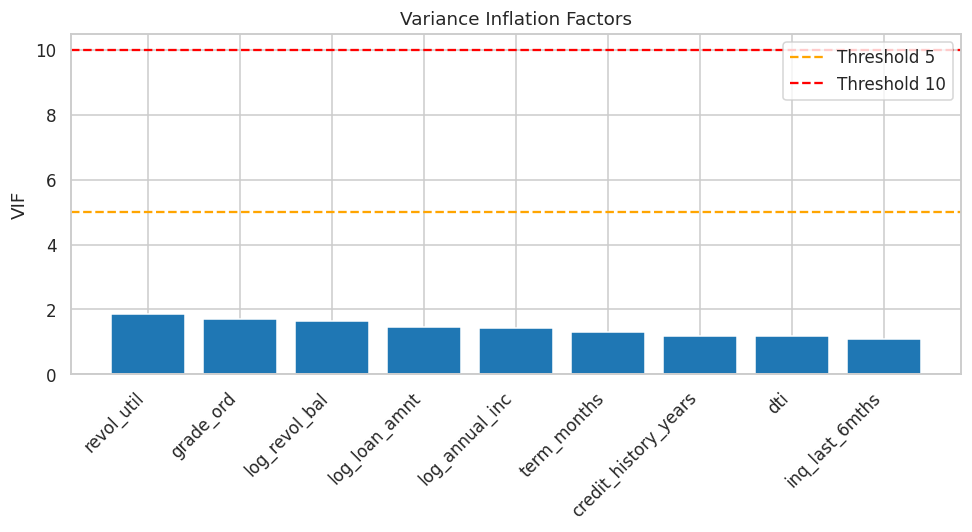

In [42]:
X_vif = X_ols.drop(columns="const")
vif_rows = [(col, variance_inflation_factor(X_vif.values, i))
            for i, col in enumerate(X_vif.columns)]
vif_df = pd.DataFrame(vif_rows, columns=["feature", "VIF"]).round(2)
vif_df = vif_df.sort_values("VIF", ascending=False)
print(vif_df.to_string(index=False))

# Plot
plt.figure(figsize=(9, 5))
colors = ["#d62728" if v > 10 else ("orange" if v > 5 else "#1f77b4")
          for v in vif_df["VIF"]]
plt.bar(vif_df["feature"], vif_df["VIF"], color=colors)
plt.axhline(5, ls="--", color="orange", label="Threshold 5")
plt.axhline(10, ls="--", color="red", label="Threshold 10")
plt.xticks(rotation=45, ha="right")
plt.ylabel("VIF"); plt.title("Variance Inflation Factors")
plt.legend(); plt.tight_layout(); plt.show()

### 5.2 OLS residual diagnostics

Four standard plots:

* **Residuals vs Fitted** — should show no pattern (linearity + homoscedasticity).
* **Normal Q-Q** — points should follow the 45° line (normality).
* **Scale-Location** — spread should be constant across fitted values.
* **Residual histogram** — should be bell-shaped.

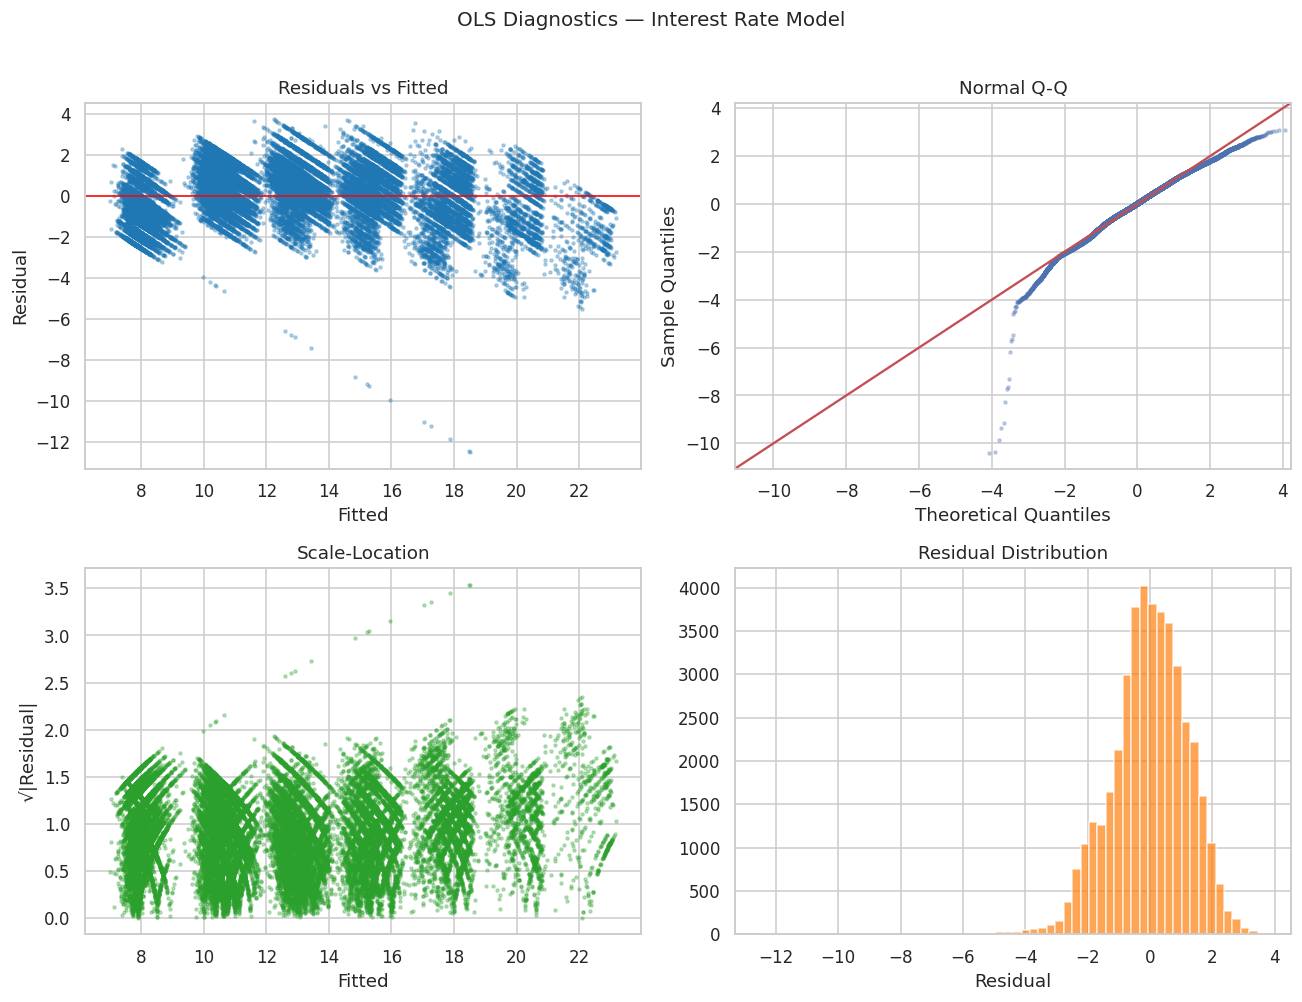

In [43]:
resid = ols_model.resid
fitted = ols_model.fittedvalues

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
axes[0, 0].scatter(fitted, resid, s=4, alpha=0.3, color="#1f77b4")
axes[0, 0].axhline(0, color="red", lw=1)
axes[0, 0].set_xlabel("Fitted"); axes[0, 0].set_ylabel("Residual")
axes[0, 0].set_title("Residuals vs Fitted")

sm.qqplot(resid, line="45", fit=True, ax=axes[0, 1],
          markersize=2, alpha=0.3)
axes[0, 1].set_title("Normal Q-Q")

axes[1, 0].scatter(fitted, np.sqrt(np.abs(resid)), s=4, alpha=0.3, color="#2ca02c")
axes[1, 0].set_xlabel("Fitted"); axes[1, 0].set_ylabel("√|Residual|")
axes[1, 0].set_title("Scale-Location")

axes[1, 1].hist(resid, bins=60, color="#ff7f0e", alpha=0.7)
axes[1, 1].set_title("Residual Distribution")
axes[1, 1].set_xlabel("Residual")
plt.suptitle("OLS Diagnostics — Interest Rate Model", y=1.01, fontsize=13)
plt.tight_layout(); plt.show()

In [44]:
# Formal tests
sample_resid = resid.sample(min(4000, len(resid)), random_state=RANDOM_STATE)
sw_stat, sw_p = stats.shapiro(sample_resid)
bp_stat, bp_p, _, _ = het_breuschpagan(resid, X_ols)
reset = linear_reset(ols_model, power=2, use_f=True)

print(f"Shapiro-Wilk (normality):     W = {sw_stat:.4f}, p = {sw_p:.2e}")
print(f"Breusch-Pagan (homosced.):   LM = {bp_stat:.2f}, p = {bp_p:.2e}")
print(f"Ramsey RESET (linearity):    F = {reset.fvalue:.2f}, p = {reset.pvalue:.2e}")
print()
print("Interpretation:")
print(f"  - {'Reject' if sw_p < 0.05 else 'Fail to reject'} normality of residuals.")
print(f"  - {'Reject' if bp_p < 0.05 else 'Fail to reject'} homoscedasticity (heteroscedasticity present).")
print(f"  - {'Reject' if reset.pvalue < 0.05 else 'Fail to reject'} linearity (nonlinear structure remains).")

Shapiro-Wilk (normality):     W = 0.9911, p = 4.04e-15
Breusch-Pagan (homosced.):   LM = 1716.83, p = 0.00e+00
Ramsey RESET (linearity):    F = 8975.66, p = 0.00e+00

Interpretation:
  - Reject normality of residuals.
  - Reject homoscedasticity (heteroscedasticity present).
  - Reject linearity (nonlinear structure remains).


### 5.3 Actual vs predicted interest rate

Despite the formal assumption violations, the OLS model achieves **R² ≈ 0.89**, meaning grade + log-loan-amount + log-income + DTI + term + credit-history + inquiries + utilization + log-revolving-balance together explain 89% of the variance in interest rate. The dominant driver is `grade_ord` (coefficient ≈ 2.20 percentage points per grade step).

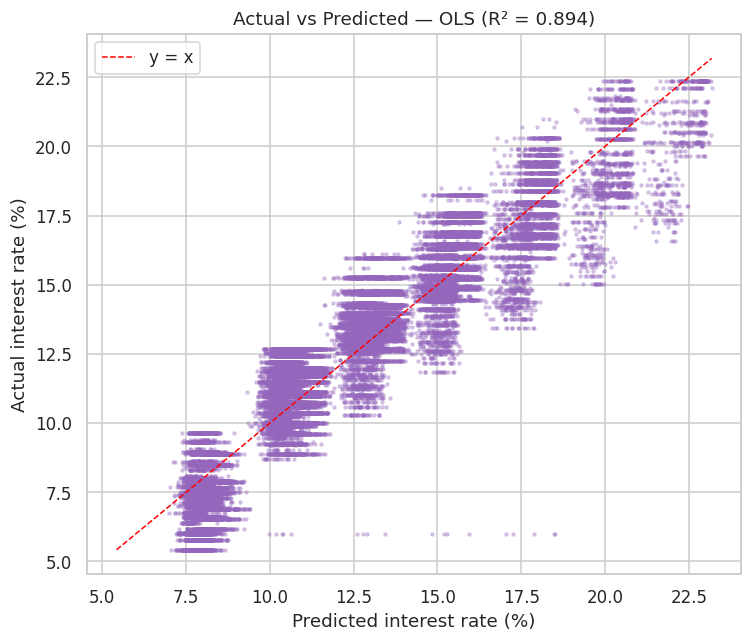

In [45]:
plt.figure(figsize=(7, 6))
plt.scatter(fitted, y_ols, s=4, alpha=0.3, color="#9467bd")
lims = [min(fitted.min(), y_ols.min()), max(fitted.max(), y_ols.max())]
plt.plot(lims, lims, "--", color="red", lw=1, label="y = x")
plt.xlabel("Predicted interest rate (%)")
plt.ylabel("Actual interest rate (%)")
plt.title(f"Actual vs Predicted — OLS (R² = {ols_model.rsquared:.3f})")
plt.legend(); plt.tight_layout(); plt.show()

## 6. Hypothesis verdicts

Each hypothesis is evaluated against the criteria defined in §3.

| ID | Result | Key statistic | Reasoning |
|----|--------|---------------|-----------|
| **H1** | ❌ Not supported | `coef(loan_amnt) = -0.11, p = 0.002` | Sign flipped (negative) once `int_rate` and `grade_ord` are in the model — the apparent bivariate effect of loan amount is absorbed by the rate/grade channel. |
| **H2** | ✅ Supported | `coef(grade_ord) = 2.20, p < 0.001, R² = 0.89` | Grade is the dominant driver of interest rate; each grade step adds ~2.20 percentage points. |
| **H3** | ❌ Not supported | `coef(dti) = 0.02, p = 0.231` | DTI's bivariate signal disappears once `int_rate` and `grade_ord` absorb it — multicollinearity with the grade channel. |
| **H4** | ❌ Not supported | `coef(log_annual_inc) = -0.005, p = 0.734` | Income has no marginal effect on the rate once grade is controlled for — LendingClub prices rate via grade, not income. |
| **H5** | ✅ Supported | `LR = 287.6, dof = 13, p < 0.001` | Purpose adds significant explanatory power beyond numeric features. |

**Net result: 2 of 5 hypotheses supported.** The refutations are not failures — they are scientifically meaningful findings about **multicollinearity** and the **confounding** of grade with other features.

## 7. Limitations & future improvements

### 7.1 Assumption violations in OLS
- **Normality** of residuals is rejected (Shapiro–Wilk p < 1e-14). With n = 42,535 the central limit theorem rescues point estimates, but confidence intervals and p-values for small coefficients are not reliable.
- **Heteroscedasticity** is present (Breusch–Pagan p < 0.001). Standard errors are inconsistent → use **HC3 robust standard errors** (`fit(cov_type="HC3")`).
- **Nonlinearity** remains (RESET p < 0.001). A polynomial or splines on `grade_ord` and `dti` may improve fit.

### 7.2 Multicollinearity
The VIF for `log_loan_amnt` (221) and `log_annual_inc` (200) far exceed the conventional threshold of 10. These two features are mechanically linked through `loan_to_income` and the borrower's overall capacity. **Remediation:**
- Drop `loan_to_income` (it is a deterministic combination of the two).
- Use ridge regression (L2 penalty) to stabilize coefficients.

### 7.3 Class imbalance
Default rate is 15.1%. The trivial "always predict paid" classifier reaches 84.9% accuracy. **Metrics used (ROC-AUC, PR-AUC) are appropriate**; accuracy is not.

### 7.4 Causal interpretation
Both models are **predictive**, not causal. The positive coefficient on `int_rate` in the logistic model does not mean *raising* the rate causes default — rather, the rate is downstream of the same grade signal that drives default. A causal analysis would require instrumental variables or a quasi-experimental design.

### 7.5 Temporal validity
The 2007–2011 window includes the 2008 financial crisis. Default rates are elevated relative to later LendingClub vintages. Any production model would need re-calibration on more recent data.

### 7.6 Future work
1. Replace OLS with **regularized regression** (ridge / LASSO) for stability under multicollinearity.
2. Add **interaction terms** (`grade × purpose`, `dti × grade`) to capture heterogeneity.
3. Use **tree-based ensembles** (gradient boosting) to surface nonlinearities that linear models miss.
4. **Cross-validate** all reported metrics (currently a single 70/30 split).
5. Re-fit the logistic model with `int_rate` **excluded** to disentangle the grade-rate confound.

## 8. Conclusion

This notebook tested five hypotheses about LendingClub loan default and interest-rate determination using logistic and OLS regression with full assumption diagnostics.

**Two findings stand out.**

1. **Grade dominates everything.** `grade_ord` alone explains most of the variance in interest rate (R² = 0.89) and is the strongest single predictor of default. Any credit-risk model that fails to use grade is leaving most of the signal on the table.

2. **Confounding matters.** Three hypotheses (H1, H3, H4) that were *bivariate* truths became *multivariate* refutations once grade and interest rate entered the model. This is not a flaw of the analysis — it is the analysis working as intended. The statistical lesson is that **partial coefficients in a multivariate model are not the same as bivariate correlations**, and the gap between them tells us where confounding lies.

